# Imports


In [3]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import pandas as pd
import os
import random
import numpy as np
from PIL import Image
import time
from tqdm import tqdm

IMAGENET_ROOT = "/mnt/lustre/datasets/ImageNet2012"

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Set random seeds for reproducibility
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

Using device: cuda


# Functions



In [4]:
def load_vit_model():
    """Load ViT-B model from torchvision"""
    print("Loading ViT-B model from torchvision...")
    model = torchvision.models.vit_b_16(weights=torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1)
    model = model.to(device)
    model.eval()
    print("ViT-B model loaded successfully!")
    return model

def create_imagenet_dataset(root_dir):
    """Create ImageNet dataset with proper transforms"""
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406],
                           std=[0.229, 0.224, 0.225])
    ])

    # Load ImageNet training dataset
    dataset = torchvision.datasets.ImageNet(root=root_dir, split='train', transform=transform)
    return dataset

def get_random_subset(dataset, num_samples=100000):
    """Get a random subset of the dataset"""
    total_size = len(dataset)
    indices = random.sample(range(total_size), min(num_samples, total_size))
    subset = Subset(dataset, indices)
    return subset, indices

def compute_losses(model, dataloader, indices):
    """Compute cross-entropy losses for all images in the dataloader"""
    criterion = nn.CrossEntropyLoss(reduction='none')
    losses = []
    image_paths = []

    print(f"Computing losses for {len(dataloader.dataset)} images...")

    with torch.no_grad():
        for batch_idx, (images, labels) in enumerate(tqdm(dataloader)):
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Compute losses
            batch_losses = criterion(outputs, labels)

            # Store losses
            losses.extend(batch_losses.cpu().numpy())

            # Store corresponding image paths
            batch_start_idx = batch_idx * dataloader.batch_size
            for i in range(len(batch_losses)):
                dataset_idx = indices[batch_start_idx + i]
                # Get the actual image path from the original dataset
                sample = dataloader.dataset.dataset.samples[dataset_idx]
                image_paths.append(sample[0])  # sample[0] is the path

    return losses, image_paths

def save_results_to_csv(losses, image_paths, output_file):
    """Save results to CSV file"""
    df = pd.DataFrame({
        'image_path': image_paths,
        'cross_entropy_loss': losses
    })
    df.to_csv(output_file, index=False)
    print(f"Results saved to {output_file}")
    return df

In [5]:
# Main execution
print("Starting ViT-B loss computation on ImageNet...")

# Step 1: Load ViT-B model
model = load_vit_model()

# Step 2: Create ImageNet dataset and dataloader
print(f"Loading ImageNet dataset from {IMAGENET_ROOT}...")
dataset = create_imagenet_dataset(IMAGENET_ROOT)
print(f"Total ImageNet training images: {len(dataset)}")

# Step 3: Get random subset of 100,000 images
subset, indices = get_random_subset(dataset, num_samples=100000)
print(f"Selected {len(subset)} random images")

# Step 4: Create dataloader for fast reading
batch_size = 64  # Adjust based on your GPU memory
num_workers = 8  # Adjust based on your system

dataloader = DataLoader(
    subset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True
)

print(f"Created dataloader with batch_size={batch_size}, num_workers={num_workers}")

Starting ViT-B loss computation on ImageNet...
Loading ViT-B model from torchvision...


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /home/oh/arubinstein17/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


  0%|          | 0.00/330M [00:00<?, ?B/s]

ViT-B model loaded successfully!
Loading ImageNet dataset from /mnt/lustre/datasets/ImageNet2012...
Total ImageNet training images: 1281167
Selected 100000 random images
Created dataloader with batch_size=64, num_workers=8


In [6]:
# Step 5: Compute losses and save results
print("Computing cross-entropy losses...")
start_time = time.time()

losses, image_paths = compute_losses(model, dataloader, indices)

end_time = time.time()
print(f"Computation completed in {end_time - start_time:.2f} seconds")

# Step 6: Save results to CSV
output_file = "imagenet_vit_losses.csv"
df = save_results_to_csv(losses, image_paths, output_file)

# Display summary statistics
print(f"\nSummary Statistics:")
print(f"Total images processed: {len(losses)}")
print(f"Mean loss: {np.mean(losses):.4f}")
print(f"Std loss: {np.std(losses):.4f}")
print(f"Min loss: {np.min(losses):.4f}")
print(f"Max loss: {np.max(losses):.4f}")

# Show top 10 highest loss samples
print(f"\nTop 10 highest loss samples:")
top_losses = df.nlargest(10, 'cross_entropy_loss')
for idx, row in top_losses.iterrows():
    print(f"Loss: {row['cross_entropy_loss']:.4f} - {row['image_path']}")

print(f"\nResults saved to: {output_file}")


Computing cross-entropy losses...
Computing losses for 100000 images...


100%|██████████| 1563/1563 [04:14<00:00,  6.14it/s]


Computation completed in 254.72 seconds
Results saved to imagenet_vit_losses.csv

Summary Statistics:
Total images processed: 100000
Mean loss: 0.3505
Std loss: 0.6815
Min loss: 0.0017
Max loss: 9.4594

Top 10 highest loss samples:
Loss: 9.4594 - /mnt/lustre/datasets/ImageNet2012/train/n02093428/n02093428_5135.JPEG
Loss: 9.0999 - /mnt/lustre/datasets/ImageNet2012/train/n02100583/n02100583_7439.JPEG
Loss: 8.8218 - /mnt/lustre/datasets/ImageNet2012/train/n02114712/n02114712_17658.JPEG
Loss: 8.6935 - /mnt/lustre/datasets/ImageNet2012/train/n03494278/n03494278_38476.JPEG
Loss: 8.6885 - /mnt/lustre/datasets/ImageNet2012/train/n02363005/n02363005_12854.JPEG
Loss: 8.4646 - /mnt/lustre/datasets/ImageNet2012/train/n01739381/n01739381_8071.JPEG
Loss: 8.4071 - /mnt/lustre/datasets/ImageNet2012/train/n02092339/n02092339_603.JPEG
Loss: 8.3286 - /mnt/lustre/datasets/ImageNet2012/train/n02095314/n02095314_3572.JPEG
Loss: 8.2156 - /mnt/lustre/datasets/ImageNet2012/train/n04392985/n04392985_8898.JPEG
L

In [20]:
# Visualization functions

def load_and_sort_csv(csv_path):
    """Load CSV and sort by cross-entropy loss"""
    df = pd.read_csv(csv_path)
    df_sorted = df.sort_values('cross_entropy_loss', ascending=False)
    return df_sorted

def get_class_name_from_path(image_path):
    """Extract class name from ImageNet path"""
    # ImageNet paths typically look like: /path/to/imagenet/train/n01440764/n01440764_10026.JPEG
    # The class ID is the folder name (e.g., n01440764)
    path_parts = image_path.split('/')
    for part in path_parts:
        if part.startswith('n') and len(part) == 9 and part[1:].isdigit():
            return part
    return "unknown"

def load_imagenet_classes():
    """Load ImageNet class names mapping from wnids_classes.txt"""
    try:
        # Load from the wnids_classes.txt file
        class_mapping = {}
        with open('/home/oh/arubinstein17/github/diverse-universe-public/notebooks/wnids_classes.txt', 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 3:
                    class_id = parts[0]  # e.g., n02119789
                    class_name = parts[2]  # e.g., kit_fox
                    class_mapping[class_id] = class_name
        print(f"Loaded {len(class_mapping)} class mappings from wnids_classes.txt")
        return class_mapping
    except Exception as e:
        print(f"Error loading wnids_classes.txt: {e}")
        try:
            # Fallback: try to load from torchvision's ImageNet classes
            from torchvision.datasets import ImageNet
            imagenet_classes = ImageNet(IMAGENET_ROOT, split='train').classes
            return imagenet_classes
        except:
            # Final fallback: return empty dict
            print("Warning: Could not load any class names, will use class IDs instead")
            return {}

def get_class_label(image_path, imagenet_classes):
    """Get human-readable class label from image path"""
    class_id = get_class_name_from_path(image_path)
    if class_id in imagenet_classes:
        return imagenet_classes[class_id]
    else:
        return class_id  # Return the class ID if no mapping found

def visualize_images(df, k=10, title="Images", save_path=None, imagenet_classes=None):
    """Visualize top-k or bottom-k images with their losses"""
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    if imagenet_classes is None:
        imagenet_classes = load_imagenet_classes()

    # Create figure
    cols = 5
    rows = (k + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3*rows))
    if rows == 1:
        axes = axes.reshape(1, -1)

    fig.suptitle(title, fontsize=16, fontweight='bold')

    for idx in range(k):
        row = idx // cols
        col = idx % cols
        ax = axes[row, col]

        # Get image info
        image_path = df.iloc[idx]['image_path']
        loss = df.iloc[idx]['cross_entropy_loss']

        try:
            # Load and display image
            img = Image.open(image_path)
            ax.imshow(img)

                        # Create title with loss, class name, and shortened path
            class_label = get_class_label(image_path, imagenet_classes)
            path_parts = image_path.split('/')
            if len(path_parts) > 3:
                short_path = '/'.join(path_parts[-3:])  # Last 3 parts of path
            else:
                short_path = image_path

            ax.set_title(f'Loss: {loss:.4f}\n{class_label}\n{short_path}', fontsize=7, fontweight='bold')
            ax.axis('off')

            # Add border color based on loss
            if loss > 5.0:  # High loss - red border
                border_color = 'red'
            elif loss > 3.0:  # Medium-high loss - orange border
                border_color = 'orange'
            elif loss > 1.0:  # Medium loss - yellow border
                border_color = 'yellow'
            else:  # Low loss - green border
                border_color = 'green'

            # Add colored border
            for spine in ax.spines.values():
                spine.set_edgecolor(border_color)
                spine.set_linewidth(3)

        except Exception as e:
            ax.text(0.5, 0.5, f'Error loading\n{image_path.split("/")[-1]}',
                   ha='center', va='center', transform=ax.transAxes, fontsize=8)

                    # Create title with loss, class name, and shortened path even for errors
            class_label = get_class_label(image_path, imagenet_classes)
            path_parts = image_path.split('/')
            if len(path_parts) > 3:
                short_path = '/'.join(path_parts[-3:])  # Last 3 parts of path
            else:
                short_path = image_path

            ax.set_title(f'Loss: {loss:.4f}\n{class_label}\n{short_path}', fontsize=7, fontweight='bold')
        ax.axis('off')

    # Hide unused subplots
    for idx in range(k, rows * cols):
        row = idx // cols
        col = idx % cols
        axes[row, col].axis('off')

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Visualization saved to {save_path}")

    plt.show()

def create_comparison_visualization(df, k=10, save_path=None, imagenet_classes=None):
    """Create side-by-side comparison of top-k and bottom-k images"""
    import matplotlib.pyplot as plt

    if imagenet_classes is None:
        imagenet_classes = load_imagenet_classes()

    # Get top-k and bottom-k
    top_k = df.head(k)
    bottom_k = df.tail(k)

    # Create figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

    # Plot top-k (highest loss)
    cols = 5
    rows = (k + cols - 1) // cols

    # Top-k subplot
    gs1 = fig.add_gridspec(rows, cols, left=0.05, right=0.45, hspace=0.3, wspace=0.3)
    ax1.remove()
    ax1 = fig.add_subplot(gs1[:, :])
    ax1.set_title(f'Top-{k} Highest Loss Images', fontsize=14, fontweight='bold', pad=20)

    for idx in range(k):
        row = idx // cols
        col = idx % cols
        ax = fig.add_subplot(gs1[row, col])

        image_path = top_k.iloc[idx]['image_path']
        loss = top_k.iloc[idx]['cross_entropy_loss']

        try:
            img = Image.open(image_path)
            ax.imshow(img)

                        # Create title with loss, class name, and shortened path
            class_label = get_class_label(image_path, imagenet_classes)
            path_parts = image_path.split('/')
            if len(path_parts) > 3:
                short_path = '/'.join(path_parts[-3:])  # Last 3 parts of path
            else:
                short_path = image_path

            ax.set_title(f'{loss:.3f}\n{class_label}\n{short_path}', fontsize=6, fontweight='bold', color='red')
            ax.axis('off')
        except Exception as e:
            ax.text(0.5, 0.5, 'Error', ha='center', va='center', transform=ax.transAxes, fontsize=8)

                        # Create title with loss, class name, and shortened path even for errors
            class_label = get_class_label(image_path, imagenet_classes)
            path_parts = image_path.split('/')
            if len(path_parts) > 3:
                short_path = '/'.join(path_parts[-3:])  # Last 3 parts of path
            else:
                short_path = image_path

            ax.set_title(f'{loss:.3f}\n{class_label}\n{short_path}', fontsize=6, fontweight='bold', color='red')
            ax.axis('off')

    # Bottom-k subplot
    gs2 = fig.add_gridspec(rows, cols, left=0.55, right=0.95, hspace=0.3, wspace=0.3)
    ax2.remove()
    ax2 = fig.add_subplot(gs2[:, :])
    ax2.set_title(f'Top-{k} Lowest Loss Images', fontsize=14, fontweight='bold', pad=20)

    for idx in range(k):
        row = idx // cols
        col = idx % cols
        ax = fig.add_subplot(gs2[row, col])

        image_path = bottom_k.iloc[idx]['image_path']
        loss = bottom_k.iloc[idx]['cross_entropy_loss']

        try:
            img = Image.open(image_path)
            ax.imshow(img)

                        # Create title with loss, class name, and shortened path
            class_label = get_class_label(image_path, imagenet_classes)
            path_parts = image_path.split('/')
            if len(path_parts) > 3:
                short_path = '/'.join(path_parts[-3:])  # Last 3 parts of path
            else:
                short_path = image_path

            ax.set_title(f'{loss:.3f}\n{class_label}\n{short_path}', fontsize=6, fontweight='bold', color='green')
            ax.axis('off')
        except Exception as e:
            ax.text(0.5, 0.5, 'Error', ha='center', va='center', transform=ax.transAxes, fontsize=8)

                        # Create title with loss, class name, and shortened path even for errors
            class_label = get_class_label(image_path, imagenet_classes)
            path_parts = image_path.split('/')
            if len(path_parts) > 3:
                short_path = '/'.join(path_parts[-3:])  # Last 3 parts of path
            else:
                short_path = image_path

            ax.set_title(f'{loss:.3f}\n{class_label}\n{short_path}', fontsize=6, fontweight='bold', color='green')
            ax.axis('off')

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Comparison visualization saved to {save_path}")

    plt.show()

def analyze_loss_distribution(df):
    """Analyze and visualize the loss distribution"""
    import matplotlib.pyplot as plt
    import seaborn as sns

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Histogram
    axes[0, 0].hist(df['cross_entropy_loss'], bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    axes[0, 0].set_title('Distribution of Cross-Entropy Losses', fontweight='bold')
    axes[0, 0].set_xlabel('Cross-Entropy Loss')
    axes[0, 0].set_ylabel('Frequency')
    axes[0, 0].axvline(df['cross_entropy_loss'].mean(), color='red', linestyle='--', label=f'Mean: {df["cross_entropy_loss"].mean():.3f}')
    axes[0, 0].legend()

    # Box plot
    axes[0, 1].boxplot(df['cross_entropy_loss'])
    axes[0, 1].set_title('Box Plot of Cross-Entropy Losses', fontweight='bold')
    axes[0, 1].set_ylabel('Cross-Entropy Loss')

    # Log scale histogram
    axes[1, 0].hist(df['cross_entropy_loss'], bins=50, alpha=0.7, color='lightcoral', edgecolor='black')
    axes[1, 0].set_title('Distribution of Cross-Entropy Losses (Log Scale)', fontweight='bold')
    axes[1, 0].set_xlabel('Cross-Entropy Loss')
    axes[1, 0].set_ylabel('Frequency (Log Scale)')
    axes[1, 0].set_yscale('log')

    # Cumulative distribution
    sorted_losses = np.sort(df['cross_entropy_loss'])
    cumulative = np.arange(1, len(sorted_losses) + 1) / len(sorted_losses)
    axes[1, 1].plot(sorted_losses, cumulative, linewidth=2)
    axes[1, 1].set_title('Cumulative Distribution of Losses', fontweight='bold')
    axes[1, 1].set_xlabel('Cross-Entropy Loss')
    axes[1, 1].set_ylabel('Cumulative Probability')
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Print statistics
    print(f"Loss Statistics:")
    print(f"  Mean: {df['cross_entropy_loss'].mean():.4f}")
    print(f"  Median: {df['cross_entropy_loss'].median():.4f}")
    print(f"  Std: {df['cross_entropy_loss'].std():.4f}")
    print(f"  Min: {df['cross_entropy_loss'].min():.4f}")
    print(f"  Max: {df['cross_entropy_loss'].max():.4f}")
    print(f"  25th percentile: {df['cross_entropy_loss'].quantile(0.25):.4f}")
    print(f"  75th percentile: {df['cross_entropy_loss'].quantile(0.75):.4f}")
    print(f"  90th percentile: {df['cross_entropy_loss'].quantile(0.90):.4f}")
    print(f"  95th percentile: {df['cross_entropy_loss'].quantile(0.95):.4f}")
    print(f"  99th percentile: {df['cross_entropy_loss'].quantile(0.99):.4f}")


Loaded 100000 images from imagenet_vit_losses.csv
Loading ImageNet class names...
Loaded 1000 class mappings from wnids_classes.txt
Loaded 1000 class names


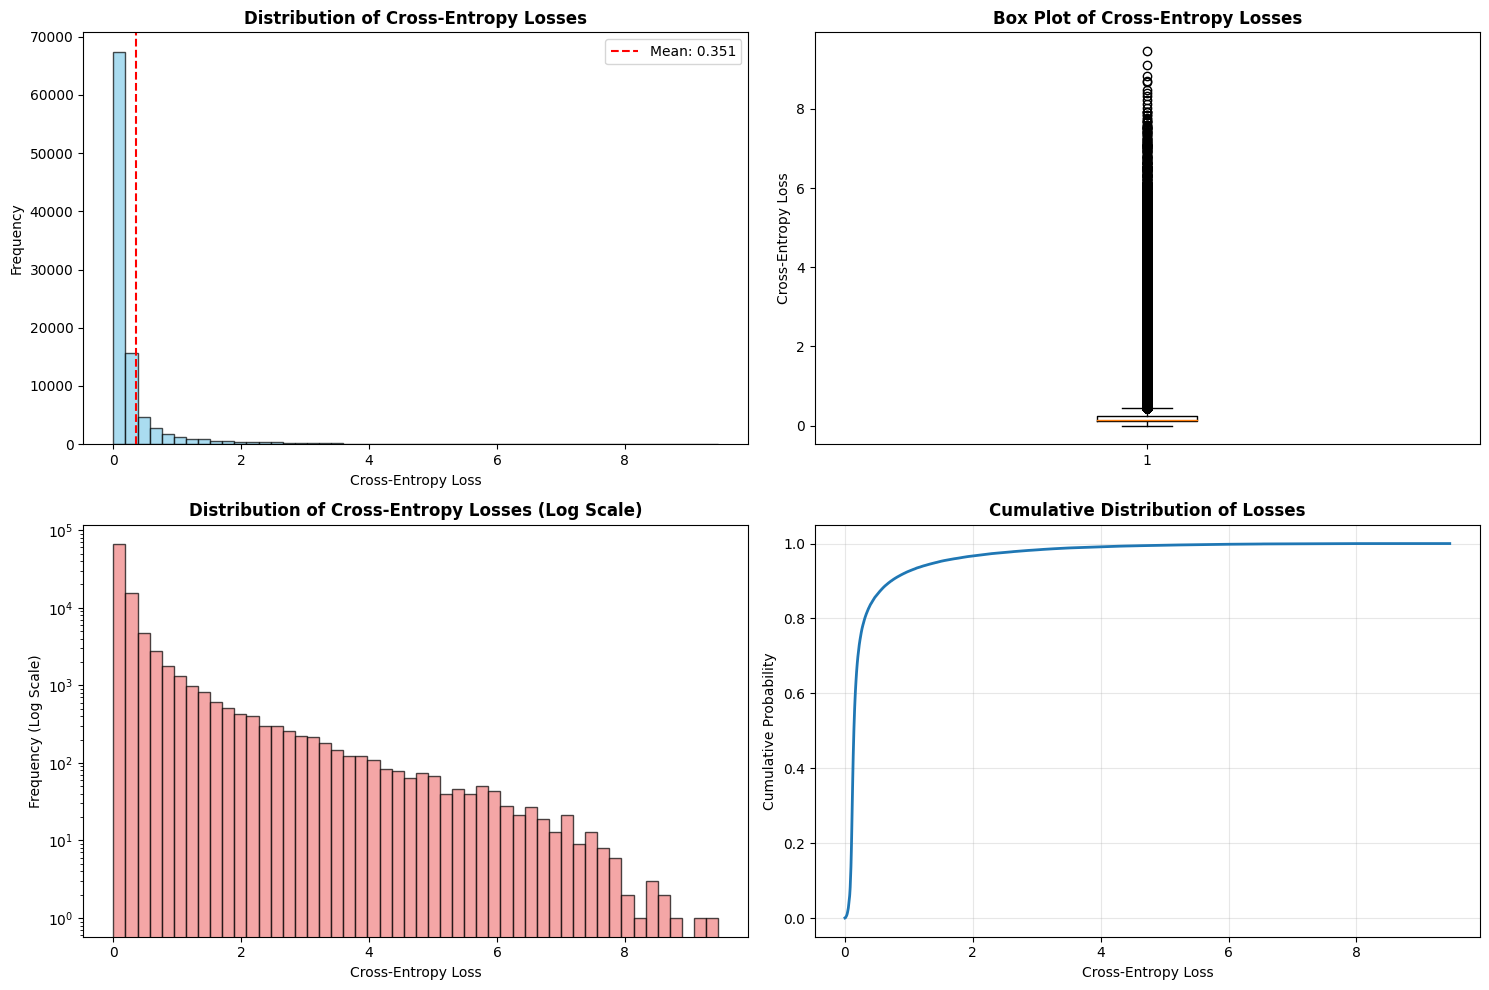

Loss Statistics:
  Mean: 0.3505
  Median: 0.1414
  Std: 0.6815
  Min: 0.0017
  Max: 9.4594
  25th percentile: 0.1101
  75th percentile: 0.2434
  90th percentile: 0.7227
  95th percentile: 1.4419
  99th percentile: 3.7722


In [21]:
# Load and visualize results from CSV
csv_file = "imagenet_vit_losses.csv"

# Load and sort the data by loss (highest to lowest)
df_sorted = load_and_sort_csv(csv_file)
print(f"Loaded {len(df_sorted)} images from {csv_file}")

# Load ImageNet class names
print("Loading ImageNet class names...")
imagenet_classes = load_imagenet_classes()
if imagenet_classes:
    print(f"Loaded {len(imagenet_classes)} class names")
else:
    print("Warning: Could not load ImageNet class names, will use class IDs instead")

# Analyze loss distribution
analyze_loss_distribution(df_sorted)


Visualizing top-40 highest loss images...
Visualization saved to top_40_highest_loss_images.png


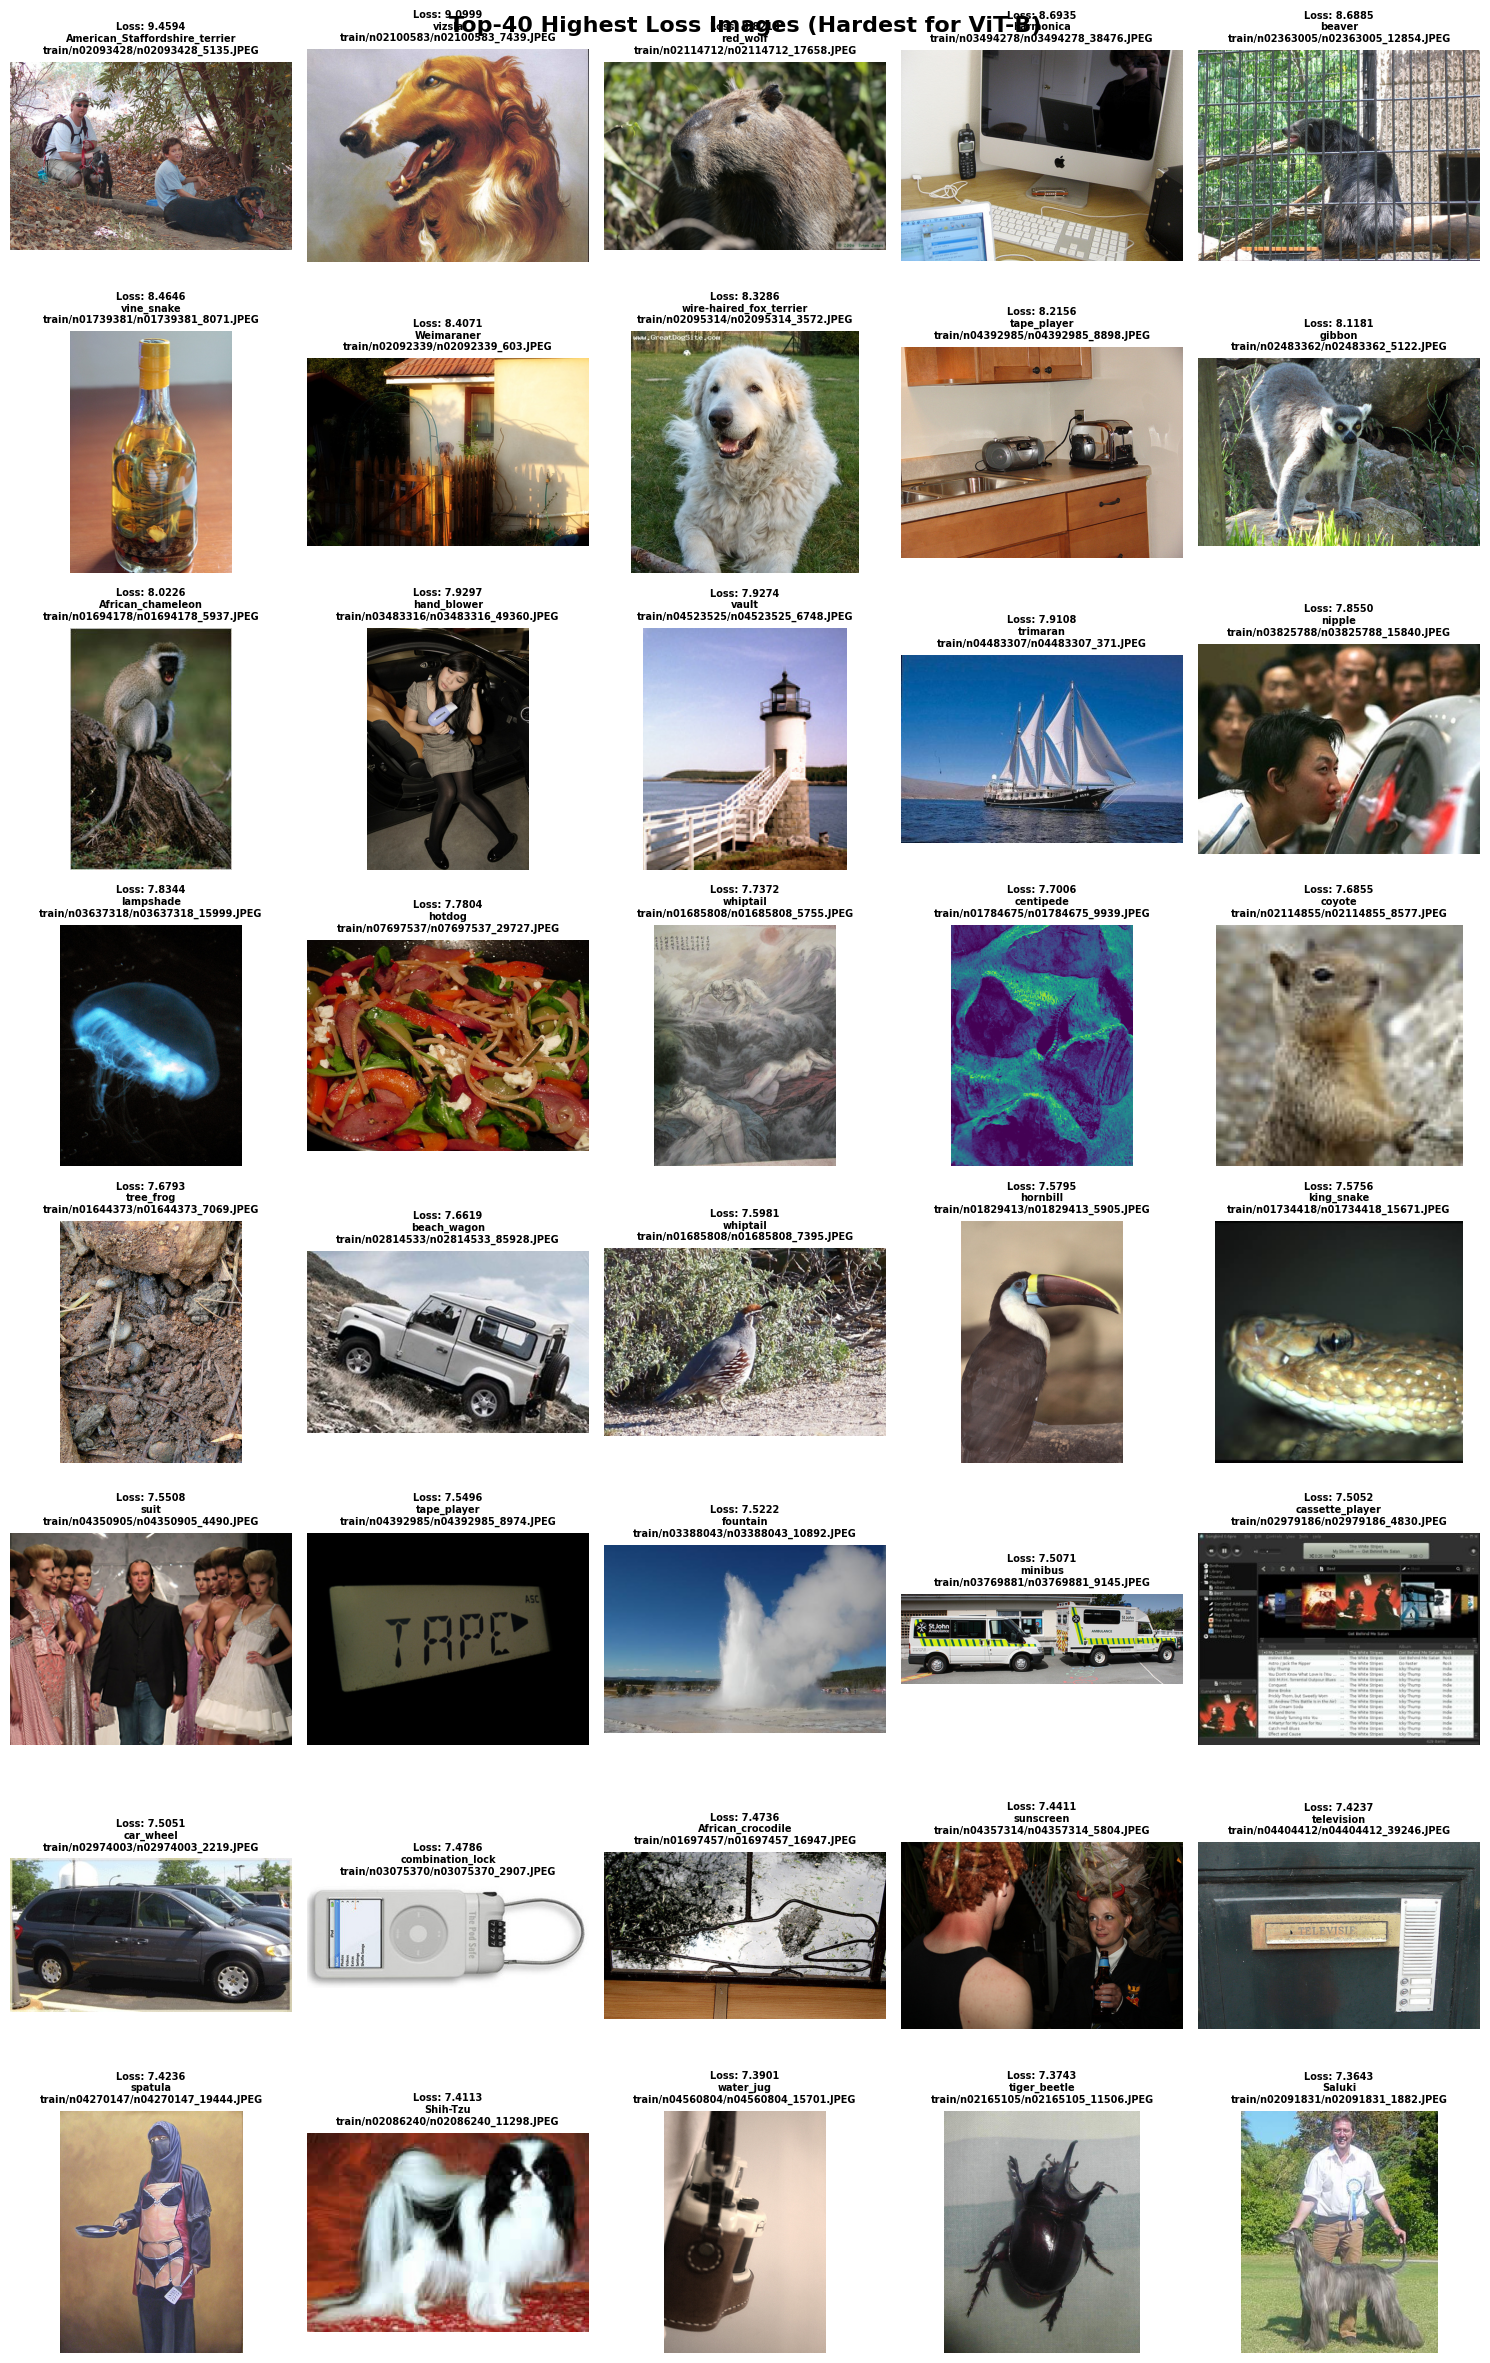

In [24]:
# Visualize top-k highest loss images
k = 40  # Number of images to show
print(f"Visualizing top-{k} highest loss images...")

visualize_images(
    df_sorted.head(k),
    k=k,
    title=f"Top-{k} Highest Loss Images (Hardest for ViT-B)",
    save_path=f"top_{k}_highest_loss_images.png",
    imagenet_classes=imagenet_classes
)


Visualizing top-20 lowest loss images...
Visualization saved to top_20_lowest_loss_images.png


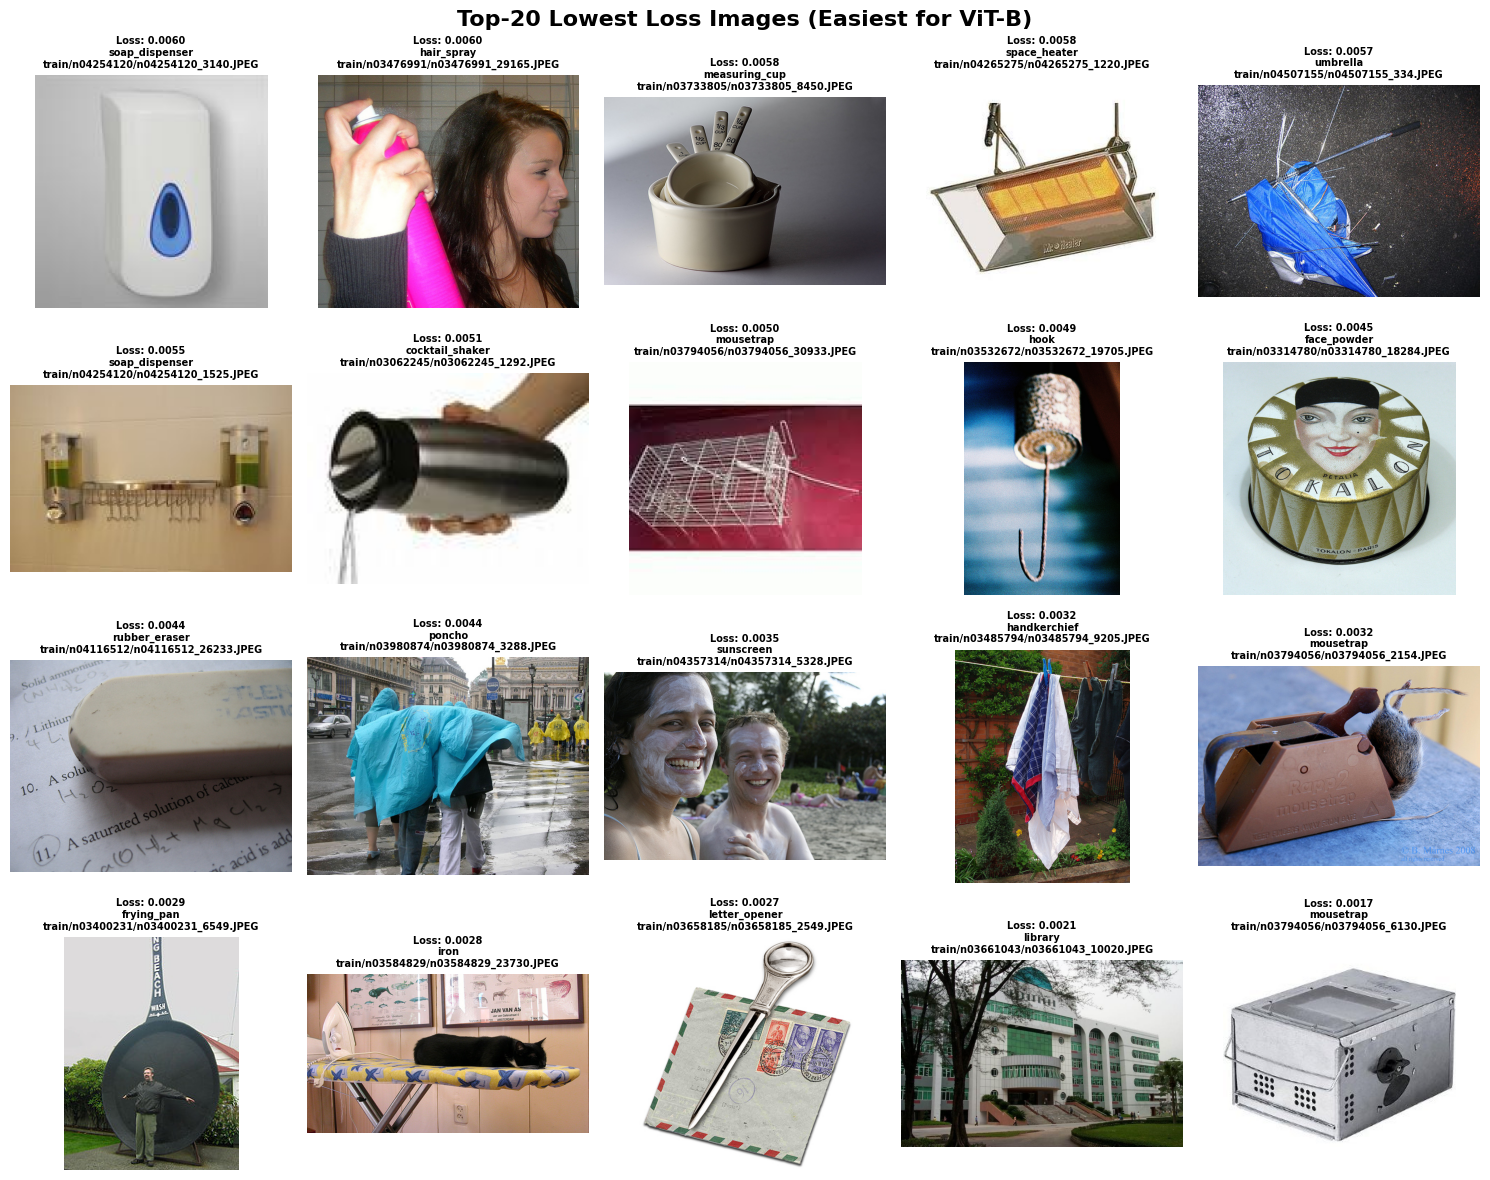

In [23]:
# Visualize bottom-k lowest loss images
print(f"Visualizing top-{k} lowest loss images...")

visualize_images(
    df_sorted.tail(k),
    k=k,
    title=f"Top-{k} Lowest Loss Images (Easiest for ViT-B)",
    save_path=f"top_{k}_lowest_loss_images.png",
    imagenet_classes=imagenet_classes
)


In [ ]:
# Create side-by-side comparison visualization
print("Creating side-by-side comparison of highest vs lowest loss images...")

create_comparison_visualization(
    df_sorted,
    k=10,  # Show 10 images each
    save_path="comparison_highest_vs_lowest_loss.png",
    imagenet_classes=imagenet_classes
)


In [ ]:
# Additional analysis: Show specific loss ranges
print("Analyzing different loss ranges...")

# High loss images (top 1%)
high_loss_threshold = df_sorted['cross_entropy_loss'].quantile(0.99)
high_loss_images = df_sorted[df_sorted['cross_entropy_loss'] >= high_loss_threshold]
print(f"Images with loss >= {high_loss_threshold:.3f} (top 1%): {len(high_loss_images)}")

# Low loss images (bottom 1%)
low_loss_threshold = df_sorted['cross_entropy_loss'].quantile(0.01)
low_loss_images = df_sorted[df_sorted['cross_entropy_loss'] <= low_loss_threshold]
print(f"Images with loss <= {low_loss_threshold:.3f} (bottom 1%): {len(low_loss_images)}")

# Show some examples from extreme ranges
if len(high_loss_images) > 0:
    print("\nExamples from highest loss range:")
        visualize_images(
        high_loss_images.head(10),
        k=min(10, len(high_loss_images)),
        title=f"Extreme High Loss Images (>= {high_loss_threshold:.3f})",
        save_path="extreme_high_loss_images.png",
        imagenet_classes=imagenet_classes
    )

if len(low_loss_images) > 0:
    print("\nExamples from lowest loss range:")
        visualize_images(
        low_loss_images.head(10),
        k=min(10, len(low_loss_images)),
        title=f"Extreme Low Loss Images (<= {low_loss_threshold:.3f})",
        save_path="extreme_low_loss_images.png",
        imagenet_classes=imagenet_classes
    )
